<a href="https://colab.research.google.com/github/everettallen2205-alt/Hurricane-Project/blob/main/Hurricane_Data_Investigation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv('/content/Hurricane Data.csv')
df

,Year,Name,Category,Rain Inch.,Highest Wind Speed,Damage(USD),Fatalities,Affected Areas
0,2000,Debby,Category 1,28.00,85,737000,1,"Lesser Antilles, Puerto Rico, Hispaniola, Turk..."
1,2000,Gordon,Category 1,9.48,80,5100000,26,"Central America (particularly Belize), Yucatán..."
2,2000,Helene,TS,9.56,70,16000000,2,"Lesser Antilles, Puerto Rico, Hispaniola, Jama..."
3,2000,Leslie,TS,17.50,45,950000000,3,"Cuba, Bahamas, Florida, Bermuda, Atlantic Cana..."
4,2001,Allison,TS,40.00,60,9000000000,55,"Texas, Louisiana, Mississippi, Alabama, Georgi..."
...,...,...,...,...,...,...,...,...
120,2022,Alex,TS,11.90,70,NaN,4,"Yucatán Peninsula, western Cuba, Florida, the ..."
121,2022,Ian,Category 5,31.52,160,113000000000,161,"Trinidad and Tobago, Venezuela, Colombia, ABC ..."
122,2022,Nicole,Category 1,8.00,75,1000000000,11,"Dominican Republic, Puerto Rico, The Bahamas, ..."
123,2023,Idalia,Category 4,5.50,130,3600000000,12,"Yucatán Peninsula, Cayman Islands, Western Cub..."


In [2]:
# Filling in and fixing a typo in the 'Damage(USD)' column
damageUSD = pd.to_numeric(df['Damage(USD)'].replace({'5.030,000,000':5030000000}))
damageUSD = damageUSD.fillna(damageUSD.mean())
df['Damage(USD)'] = damageUSD

# Filling in the 'Rain Inch.' column
df['Rain Inch.'] = df['Rain Inch.'].fillna(df['Rain Inch.'].mean())

# Making a new column to make the 'category' column useful in calculations and graphs
numcat = []
for entry in df['Category']:
  if entry == 'TS':
    numcat.append(0)
  elif entry == 'Category 1':
    numcat.append(1)
  elif entry == 'Category 2':
    numcat.append(2)
  elif entry == 'Category 3':
    numcat.append(3)
  elif entry == 'Category 4':
    numcat.append(4)
  else:
    numcat.append(5)

df['Category Level'] = numcat

In [3]:
high_death = df[df['Fatalities'] > 50]
high_death

,Year,Name,Category,Rain Inch.,Highest Wind Speed,Damage(USD),Fatalities,Affected Areas,Category Level
4,2001,Allison,TS,40.00,60,9.000000e+09,55,"Texas, Louisiana, Mississippi, Alabama, Georgi...",0
22,2003,Isabel,Category 5,1.34,165,3.600000e+09,51,"Lesser Antilles, Greater Antilles, Lucayan Arc...",5
31,2005,Dennis,Category 4,8.70,150,3.980000e+09,88,"Windward Islands, Greater Antilles, Southeaste...",4
34,2005,Rita,Category 5,5.04,58,1.850000e+10,120,"Hispaniola, Turks and Caicos Islands, Bahamas,...",5
36,2005,Wilma,Category 5,13.26,135,2.650000e+10,52,"Mexico, Florida, Bahamas",5
44,2007,Noel,Category 1,17.23,80,5.800000e+08,222,"Leeward Islands, Puerto Rico, Hispaniola, Jama...",1
50,2008,Gustav,Category 4,10.75,155,8.310000e+09,153,"Lesser Antilles, Greater Antilles, United Stat...",4
51,2008,Hanna,Category 1,12.00,85,1.600000e+08,537,"Puerto Rico, Turks and Caicos Islands, Bahamas...",1
52,2008,Ike,Category 4,10.00,145,3.800000e+10,214,"Lucayan Archipelago, Hispanialo, Cuba, Cayman ...",4
58,2010,Alex,Category 2,23.10,110,1.520000e+09,73,"Greater Antilles, Central America, Yucatán Pen...",2


Text(0.5, 1.0, 'Fatalities to Damage Where Fatalities Is Greater Than 50')

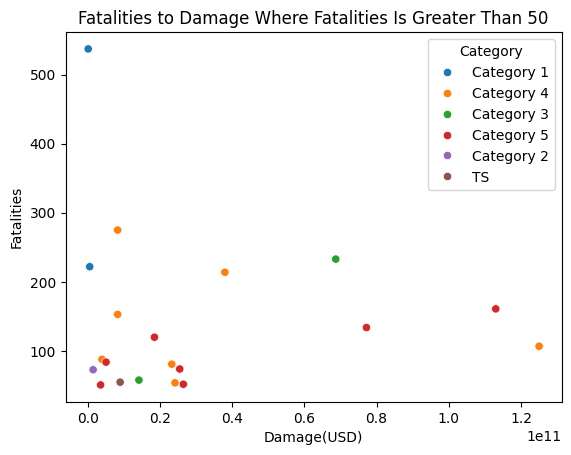

In [4]:
# The graph was hard to read because of an outlier in the fatalities column was increasing the ceiling to a little over 3000
ignoredf = high_death.sort_values(by = 'Fatalities', ascending=False).reset_index().drop(0)
sns.scatterplot(x = 'Damage(USD)', y = 'Fatalities', data = ignoredf, hue = 'Category')
plt.title('Fatalities to Damage Where Fatalities Is Greater Than 50')

Text(0.5, 1.0, 'Heatmap of Rain Inches to Top Wind Speed')

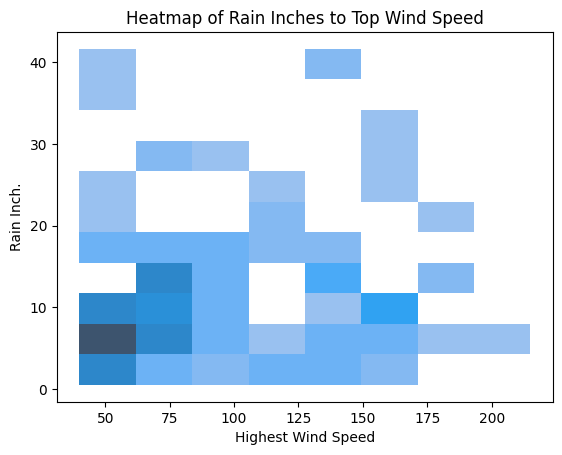

In [5]:
sns.histplot(x = 'Highest Wind Speed', y = 'Rain Inch.', data = df)
plt.title('Heatmap of Rain Inches to Top Wind Speed')

Text(0.5, 1.0, 'Count of Hurricanes With Death Tolls Greater Than 50')

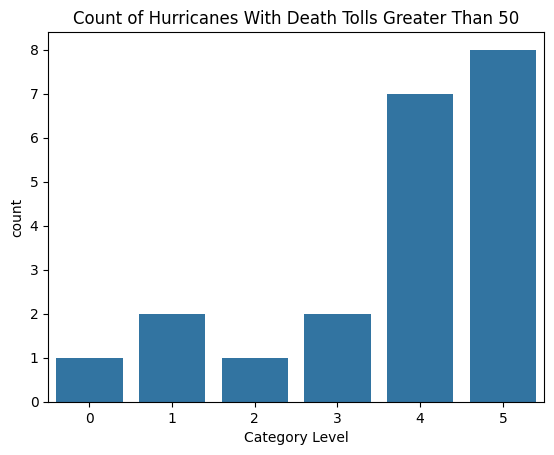

In [6]:
sns.countplot(x = 'Category Level', data = high_death)
plt.title('Count of Hurricanes With Death Tolls Greater Than 50')

In [7]:
df.describe()

,Year,Rain Inch.,Highest Wind Speed,Damage(USD),Fatalities,Category Level
count,125.000000,125.000000,125.000000,1.250000e+02,125.000000,125.000000
mean,2010.936000,11.318250,93.400000,6.966696e+09,55.176000,1.672000
std,6.854177,8.515609,40.608874,1.955137e+10,279.067545,1.895564
min,2000.000000,0.500000,40.000000,1.000000e+04,0.000000,0.000000
25%,2005.000000,5.350000,60.000000,2.500000e+07,2.000000,0.000000
50%,2010.000000,9.000000,75.000000,5.000000e+08,6.000000,1.000000
75%,2017.000000,15.000000,130.000000,6.966696e+09,34.000000,4.000000
max,2023.000000,41.650000,215.000000,1.250000e+11,3059.000000,5.000000


In [11]:
df[['Category', 'Fatalities', 'Rain Inch.', 'Damage(USD)']].groupby('Category').agg(
    avg_fatalities = ('Fatalities', 'mean'),
    max_fatalities = ('Fatalities', 'max'),
    avg_rain_fall = ('Rain Inch.', 'mean'),
    max_rain_fall = ('Rain Inch.', 'max'),
    total_instances = ('Category', 'count'),
    avg_damage_USD = ('Damage(USD)', 'mean'),
    max_damage_USD = ('Damage(USD)', 'max'))

,avg_fatalities,max_fatalities,avg_rain_fall,max_rain_fall,total_instances,avg_damage_USD,max_damage_USD
Category,,,,,,,
Category 1,43.636364,537,11.341818,28.00,22,1.019574e+09,6.966696e+09
Category 2,20.166667,73,16.083333,23.10,6,2.145899e+09,6.966696e+09
Category 3,47.142857,233,9.065714,21.70,7,1.372961e+10,6.870000e+10
Category 4,56.857143,275,13.469524,41.65,21,1.316452e+10,1.250000e+11
Category 5,275.714286,3059,12.216429,31.52,14,2.629736e+10,1.130000e+11
TS,7.854545,55,10.025659,40.00,55,1.723741e+09,9.000000e+09


In [12]:
df[['Year', 'Fatalities']].groupby('Year').sum('fatalites')

,Fatalities
Year,
2000,32
2001,115
2002,46
2003,62
2004,124
2005,293
2006,18
2007,318
2008,969


In [9]:
df.corr(numeric_only=True)

,Year,Rain Inch.,Highest Wind Speed,Damage(USD),Fatalities,Category Level
Year,1.000000,0.069277,0.160722,0.177469,0.086892,0.118167
Rain Inch.,0.069277,1.000000,0.108502,0.272691,-0.019657,0.126887
Highest Wind Speed,0.160722,0.108502,1.000000,0.371973,0.244078,0.922818
Damage(USD),0.177469,0.272691,0.371973,1.000000,0.466161,0.397580
Fatalities,0.086892,-0.019657,0.244078,0.466161,1.000000,0.224655
Category Level,0.118167,0.126887,0.922818,0.397580,0.224655,1.000000


# Correlation Findings
* The wind speed to category correlation is because category is defined by wind speed.
* I'm surprised to find that 'Damage' and 'Fatalites' only have a moderate correlation. I'm guessing this is because of varying evacuation efforts.
* Fatalities seems to be connected to something not in the dataset, but if I were to investigate this further I would check how country GDP correlates with fatalities.